# Experiment Analysis

In [5]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

RESULTS = Path("..") / "results" / "timings.csv"
df = pd.read_csv(RESULTS)

# Per-operation cost: every row is a batch of n_ops operations.
df["us_per_op"] = df["total_ns"] / df["n_ops"] / 1_000
for counter in ["comparisons", "nodes_visited", "rotations", "splits", "resizes"]:
    df[f"{counter}_per_op"] = df[counter] / df["n_ops"]

df[["experiment", "code_version", "machine_id", "index_type", "operation", "n_keys", "rep", "us_per_op", "comparisons_per_op"]].head()

,experiment,code_version,machine_id,index_type,operation,n_keys,rep,us_per_op,comparisons_per_op
0,E1_build,31da8dc,rachel-mac,unsorted_list,build,1000,0,0.468000,0.0
1,E1_build,31da8dc,rachel-mac,unsorted_list,build,1000,1,0.652625,0.0
2,E1_build,31da8dc,rachel-mac,unsorted_list,build,1000,2,0.315625,0.0
3,E1_build,31da8dc,rachel-mac,unsorted_list,build,1000,3,0.142958,0.0
4,E1_build,31da8dc,rachel-mac,unsorted_list,build,1000,4,0.158833,0.0


In [8]:
print(df.columns)

Index(['session_id', 'timestamp_utc', 'member', 'machine_id', 'code_version',
       'python_version', 'os', 'arch', 'cpu_model_detected', 'cpu_count',
       'mem_total_gb', 'in_docker', 'pythonhashseed', 'experiment', 'dataset',
       'key_column', 'insert_order', 'n_keys', 'operation', 'operation_param',
       'n_ops', 'rep', 'total_ns', 'index_type', 'index_param', 'comparisons',
       'nodes_visited', 'rotations', 'splits', 'resizes', 'height',
       'memory_bytes', 'notes', 'us_per_op', 'comparisons_per_op',
       'nodes_visited_per_op', 'rotations_per_op', 'splits_per_op',
       'resizes_per_op'],
      dtype='object')


In [14]:
GROUP = ["code_version", "machine_id"]

# one fixed colour per index
INDEX_COLOURS = {
    name: plt.get_cmap("tab10")(i) for i, name in enumerate(sorted(df["index_type"].dropna().unique()))
}

# E1 Analysis

In [ ]:
e1_df = df[df['experiment'] == 'E1_build']
e1_feature_list = ["experiment", "code_version", "machine_id", "index_type", "operation",
                   "n_keys", "n_ops", "rep", "total_ns"]
e1_df.head()

,experiment,code_version,machine_id,index_type,operation,n_keys,rep,us_per_op,comparisons_per_op
0,E1_build,31da8dc,rachel-mac,unsorted_list,build,1000,0,0.468000,0.0
1,E1_build,31da8dc,rachel-mac,unsorted_list,build,1000,1,0.652625,0.0
2,E1_build,31da8dc,rachel-mac,unsorted_list,build,1000,2,0.315625,0.0
3,E1_build,31da8dc,rachel-mac,unsorted_list,build,1000,3,0.142958,0.0
4,E1_build,31da8dc,rachel-mac,unsorted_list,build,1000,4,0.158833,0.0


In [9]:
# E1: How does build cost grow with n? How much memory does each index use?

# E1 ANALYSIS TO WRITE:
# - group by code_version and machine_id
# - for each index & n_keys:
# - analyze the memory_bytes per build method (averaged)
# - build a line plot, x axis = n_keys, y axis = memory_bytes, line/color = index

=== E1 memory: code_version=0dd46d8, machine=kimberly-mb ===


index_type,avl_tree,bplus_tree,hash_table,ref_bisect,ref_dict,sorted_list,unsorted_list
n_keys,,,,,,,
1000,136752.0,91808.0,278672.0,82368.0,90808.0,82512.0,65664.0
3000,408536.0,273816.0,692144.0,244664.0,296560.0,244696.0,194584.0
10000,1300016.0,891800.0,2221680.0,783968.0,840360.0,784000.0,645672.0
30000,3891288.0,2660568.0,6514144.0,2389552.0,2857976.0,2389584.0,1926928.0
60000,7371432.0,5086000.0,12178896.0,4551296.0,5585144.0,4551328.0,3860344.0
114000,13137256.0,9153776.0,21447768.0,8277784.0,10520792.0,8277816.0,7398184.0


index_type,avl_tree,bplus_tree,hash_table,ref_bisect,ref_dict,sorted_list,unsorted_list
bytes per key,,,,,,,
1000,136.8,91.8,278.7,82.4,90.8,82.5,65.7
3000,136.2,91.3,230.7,81.6,98.9,81.6,64.9
10000,130.0,89.2,222.2,78.4,84.0,78.4,64.6
30000,129.7,88.7,217.1,79.7,95.3,79.7,64.2
60000,122.9,84.8,203.0,75.9,93.1,75.9,64.3
114000,115.2,80.3,188.1,72.6,92.3,72.6,64.9


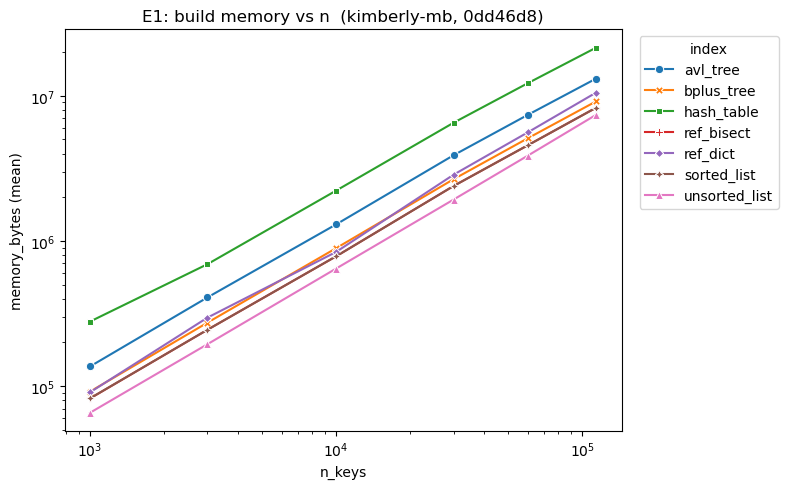

=== E1 memory: code_version=31da8dc, machine=rachel-mac ===


index_type,avl_tree,bplus_tree,hash_table,ref_bisect,ref_dict,sorted_list,unsorted_list
n_keys,,,,,,,
1000,136752.0,91808.0,278672.0,82368.0,90808.0,82512.0,65664.0
3000,408536.0,273816.0,692144.0,244664.0,296560.0,244696.0,194584.0
10000,1300016.0,891800.0,2221680.0,783968.0,840360.0,784000.0,645672.0
30000,3891288.0,2660568.0,6514144.0,2389552.0,2857976.0,2389584.0,1926928.0
60000,7371432.0,5086000.0,12178896.0,4551296.0,5585144.0,4551328.0,3860344.0
114000,13137256.0,9153776.0,21447768.0,8277784.0,10520792.0,8277816.0,7398184.0


index_type,avl_tree,bplus_tree,hash_table,ref_bisect,ref_dict,sorted_list,unsorted_list
bytes per key,,,,,,,
1000,136.8,91.8,278.7,82.4,90.8,82.5,65.7
3000,136.2,91.3,230.7,81.6,98.9,81.6,64.9
10000,130.0,89.2,222.2,78.4,84.0,78.4,64.6
30000,129.7,88.7,217.1,79.7,95.3,79.7,64.2
60000,122.9,84.8,203.0,75.9,93.1,75.9,64.3
114000,115.2,80.3,188.1,72.6,92.3,72.6,64.9


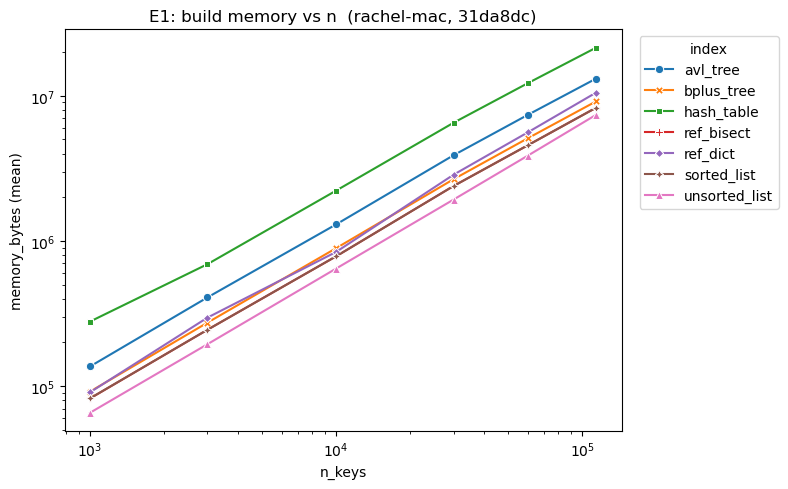

In [11]:
# E1: How does build cost grow with n? How much memory does each index use?

# Build rows only; memory_bytes is blank on rows that did not measure it.
e1 = df[(df["experiment"] == "E1_build") & (df["operation"] == "build")].dropna(subset=["memory_bytes"])

# memory_bytes is measured once per (index, n) configuration and copied onto every
# replicate's row, so the mean over reps equals that single measurement.
e1_memory = (
    e1.groupby(["code_version", "machine_id", "index_type", "n_keys"], as_index=False)["memory_bytes"]
    .mean()
)

# One table and one plot per (code_version, machine_id) so runs are never mixed.
for (version, machine), g in e1_memory.groupby(["code_version", "machine_id"]):
    print(f"=== E1 memory: code_version={version}, machine={machine} ===")

    # Mean memory (bytes) per index at each n
    table = g.pivot(index="n_keys", columns="index_type", values="memory_bytes")
    display(table.round(0))

    # Bytes per key makes the indexes comparable across sizes
    display((table.div(table.index.to_series(), axis=0)).round(1).rename_axis("bytes per key"))

    # x = n_keys, y = memory_bytes, one line/colour per index
    fig, ax = plt.subplots(figsize=(8, 5))
    sns.lineplot(
        data=g, x="n_keys", y="memory_bytes",
        hue="index_type", style="index_type", markers=True, dashes=False, ax=ax,
    )
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("n_keys")
    ax.set_ylabel("memory_bytes (mean)")
    ax.set_title(f"E1: build memory vs n  ({machine}, {version})")
    ax.legend(title="index", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()


# E2 Analysis

In [10]:
# E2: How does point-lookup cost grow with n, for hits and for misses?

# E2 ANALYSIS TO WRITE:
# - group by code_version and machine_id
# - for each index & n_keys:
# - analyze the time cost for hits and misses
# - build a framework for a line plot for one index, x axis = n_keys, y axis = time, lines for hits and misses

=== E2 bplus_tree: code_version=0dd46d8, machine=kimberly-mb ===


operation,point_hit,point_miss
n_keys,,
1000,3.735,2.928
3000,2.448,2.091
10000,2.626,2.237
30000,3.692,3.050
60000,3.870,2.969
114000,7.013,3.341


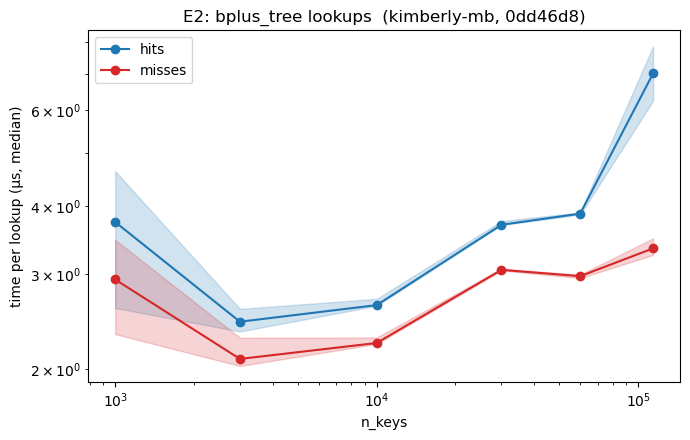

=== E2 bplus_tree: code_version=c2406c6, machine=rachel-mac ===


operation,point_hit,point_miss
n_keys,,
1000,2.493,2.194
3000,2.397,1.714
10000,2.196,1.888
30000,2.887,2.279
60000,4.214,2.682
114000,4.912,2.633


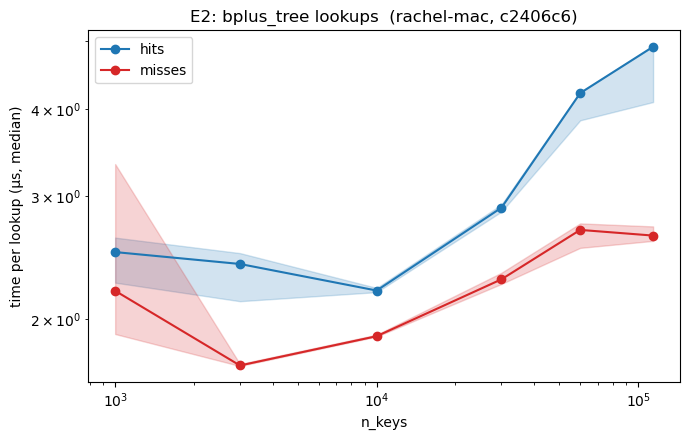

In [12]:
# E2: How does point-lookup cost grow with n, for hits and for misses?

e2 = df[
    (df["experiment"] == "E2_point_lookup")
    & (df["operation"].isin(["point_hit", "point_miss"]))
]

# Median time per lookup across the replicates, with the interquartile range,
# for every (code_version, machine, index, operation, n_keys).
e2_summary = (
    e2.groupby(["code_version", "machine_id", "index_type", "operation", "n_keys"])["us_per_op"]
    .agg(median="median", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75))
    .reset_index()
)

OP_STYLE = {"point_hit": ("hits", "tab:blue"), "point_miss": ("misses", "tab:red")}


def plot_point_lookup(summary, index_name, ax=None, title=None):
    """Line plot for ONE index: x = n_keys, y = us per lookup, one line for hits, one for misses.

    `summary` is e2_summary restricted to a single (code_version, machine_id).
    The band is the interquartile range across replicates.
    """
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 4.5))
    d = summary[summary["index_type"] == index_name]
    for op, (label, colour) in OP_STYLE.items():
        s = d[d["operation"] == op].sort_values("n_keys")
        ax.plot(s["n_keys"], s["median"], marker="o", color=colour, label=label)
        ax.fill_between(s["n_keys"], s["q25"], s["q75"], color=colour, alpha=0.2)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("n_keys")
    ax.set_ylabel("time per lookup (\u00b5s, median)")
    ax.set_title(title or f"E2: {index_name}")
    ax.legend()
    return ax


# Pick the index to inspect (any value of df["index_type"]).
E2_INDEX = "bplus_tree"

for (version, machine), g in e2_summary.groupby(["code_version", "machine_id"]):
    print(f"=== E2 {E2_INDEX}: code_version={version}, machine={machine} ===")

    # Median us/op for hits and misses at each n
    display(
        g[g["index_type"] == E2_INDEX]
        .pivot(index="n_keys", columns="operation", values="median")
        .round(3)
    )

    plot_point_lookup(g, E2_INDEX, title=f"E2: {E2_INDEX} lookups  ({machine}, {version})")
    plt.tight_layout()
    plt.show()


# E3 Analysis

In [ ]:
# E3: How does range-query cost depend on how much of the data the range covers?

# E3 ANALYSIS TO WRITE:
# - group by code_version and machine_id
# - for each index and selectivity
# - analyze search cost time

=== E3 range cost: code_version=0dd46d8, machine=kimberly-mb ===


index_type,avl_tree,bplus_tree,hash_table,ref_bisect,ref_dict,sorted_list,unsorted_list
selectivity,,,,,,,
0.0001,11.30,4150.67,10192.24,3.79,2487.53,6.70,5282.21
0.0010,40.88,4255.75,10117.32,7.87,2558.13,22.42,6032.44
0.0100,361.69,4334.74,9226.03,34.73,2590.84,144.45,5103.08
0.0500,1661.83,5653.68,13088.52,139.25,2828.98,734.68,5216.69
0.1000,3190.89,4874.52,12561.19,302.13,3168.75,2158.94,5343.54
0.2500,9527.08,6141.28,15489.91,898.97,4578.22,3675.48,6394.68


,slope,slope_se
index_type,,
avl_tree,0.870,0.046
bplus_tree,0.046,0.015
hash_table,0.050,0.021
ref_bisect,0.697,0.073
ref_dict,0.059,0.025
sorted_list,0.840,0.058
unsorted_list,0.007,0.015


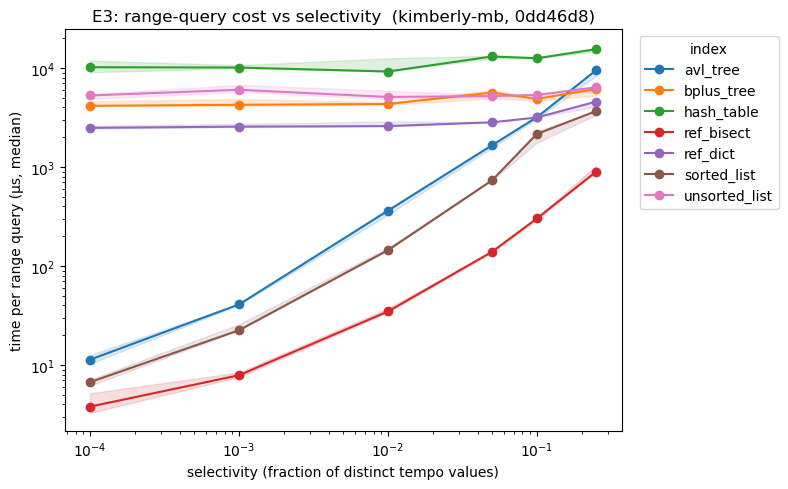

In [15]:
# E3: How does range-query cost depend on how much of the data the range covers?

def median_iqr(data, by, value="us_per_op"):
    """Median and 25th/75th percentile of `value` across replicates, per group in `by`."""
    return (
        data.groupby(by)[value]
        .agg(median="median", q25=lambda s: s.quantile(0.25), q75=lambda s: s.quantile(0.75))
        .reset_index()
    )


def plot_lines(ax, summary, x, by="index_type", logx=True, logy=True, band=True, colours=None):
    """One line per value of `by` (median) with an IQR band. Non-positive values are skipped on log axes."""
    colours = colours if colours is not None else INDEX_COLOURS
    for name, s in summary.groupby(by):
        s = s.sort_values(x)
        s = s[s["median"] > 0] if logy else s.dropna(subset=["median"])
        if s.empty:
            continue
        ax.plot(s[x], s["median"], marker="o", label=name, color=colours.get(name))
        if band:
            ax.fill_between(s[x], s["q25"], s["q75"], alpha=0.15, color=colours.get(name))
    if logx:
        ax.set_xscale("log")
    if logy:
        ax.set_yscale("log")


def loglog_slope(x, y):
    """Least-squares slope of log10(y) on log10(x) and its standard error."""
    x, y = np.log10(np.asarray(x, float)), np.log10(np.asarray(y, float))
    ok = np.isfinite(x) & np.isfinite(y)
    if ok.sum() < 3:
        return np.nan, np.nan
    (slope, _), cov = np.polyfit(x[ok], y[ok], 1, cov=True)
    return slope, float(np.sqrt(cov[0, 0]))


# ---- E3 analysis ---------------------------------------------------------------
e3 = df[df["experiment"].str.startswith("E3") & (df["operation"] == "range")].copy()
e3["selectivity"] = pd.to_numeric(e3["operation_param"])

# Median time per range query across replicates, per (version, machine, index, selectivity).
e3_summary = median_iqr(e3, GROUP + ["index_type", "selectivity"])

for (version, machine), g in e3_summary.groupby(GROUP):
    print(f"=== E3 range cost: code_version={version}, machine={machine} ===")

    # Median us per range query: rows = selectivity, columns = index
    display(g.pivot(index="selectivity", columns="index_type", values="median").round(2))

    # Empirical growth: log-log slope of time vs selectivity (about 0 = cost doesn't depend on range size)
    slopes = pd.DataFrame(
        [
            dict(index_type=name, slope=loglog_slope(s["selectivity"], s["median"])[0],
                 slope_se=loglog_slope(s["selectivity"], s["median"])[1])
            for name, s in g.groupby("index_type")
        ]
    ).set_index("index_type").round(3)
    display(slopes)

    fig, ax = plt.subplots(figsize=(8, 5))
    plot_lines(ax, g, x="selectivity")
    ax.set_xlabel("selectivity (fraction of distinct tempo values)")
    ax.set_ylabel("time per range query (\u00b5s, median)")
    ax.set_title(f"E3: range-query cost vs selectivity  ({machine}, {version})")
    ax.legend(title="index", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

# E4 Analysis

In [ ]:
# E4: How does prefix-search cost depend on prefix length?

# E4 ANALYSIS TO WRITE:
# - group by code_version and machine_id
# - for each index and prefix length
# - analyze search cost time and operations

=== E4 prefix search: code_version=0dd46d8, machine=kimberly-mb ===


index_type,avl_tree,bplus_tree,hash_table,ref_bisect,ref_dict,sorted_list,unsorted_list
prefix_length,,,,,,,
1.0,2478.0,12606.5,31607.4,285.3,6842.0,1710.6,8786.4
2.0,452.7,13346.5,32528.7,74.5,6587.9,343.9,8943.3
3.0,141.3,11766.8,35353.9,19.2,6078.5,81.0,8867.5
4.0,119.8,12535.2,32483.8,15.7,6199.4,59.6,9022.4
5.0,30.1,11960.9,31500.8,5.8,6253.0,16.3,8716.6


index_type,avl_tree,bplus_tree,hash_table,sorted_list,unsorted_list
prefix_length,,,,,
1.0,3179.4,72396.0,72396.0,3179.1,113999.0
2.0,617.0,72396.0,72396.0,616.1,113999.0
3.0,195.8,72396.0,72396.0,194.7,113999.0
4.0,175.3,72396.0,72396.0,175.2,113999.0
5.0,40.9,72396.0,72396.0,40.5,113999.0


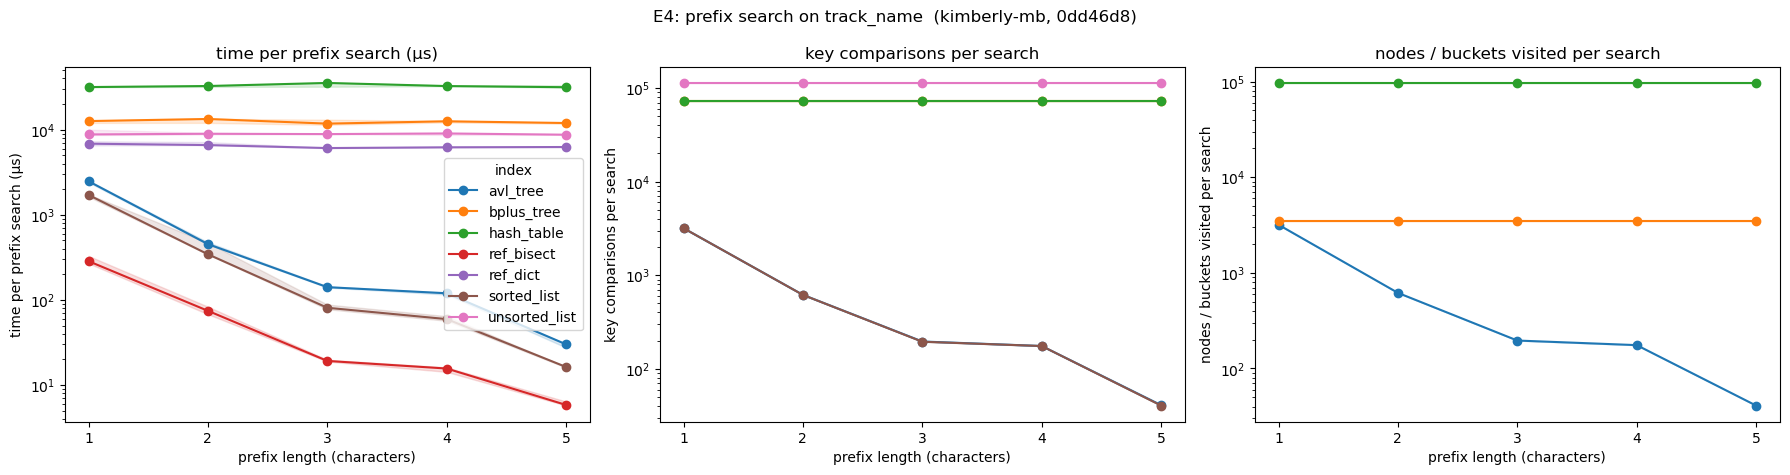

=== E4 prefix search: code_version=f24508f, machine=harshini-mba ===


index_type,avl_tree,bplus_tree,hash_table,ref_bisect,ref_dict,sorted_list,unsorted_list
prefix_length,,,,,,,
1.0,1494.8,7984.4,19127.6,134.5,3678.5,866.8,5474.5
2.0,292.9,7389.0,19539.7,39.1,3562.1,177.9,5552.0
3.0,87.7,7480.2,19149.5,14.1,3429.5,53.1,5531.8
4.0,69.5,7188.7,18715.7,10.3,3501.6,37.6,5709.5
5.0,17.5,7486.6,18429.1,5.0,3548.3,11.8,5576.1


index_type,avl_tree,bplus_tree,hash_table,sorted_list,unsorted_list
prefix_length,,,,,
1.0,3179.4,72396.0,72396.0,3179.1,113999.0
2.0,617.0,72396.0,72396.0,616.1,113999.0
3.0,195.8,72396.0,72396.0,194.7,113999.0
4.0,175.3,72396.0,72396.0,175.2,113999.0
5.0,40.9,72396.0,72396.0,40.5,113999.0


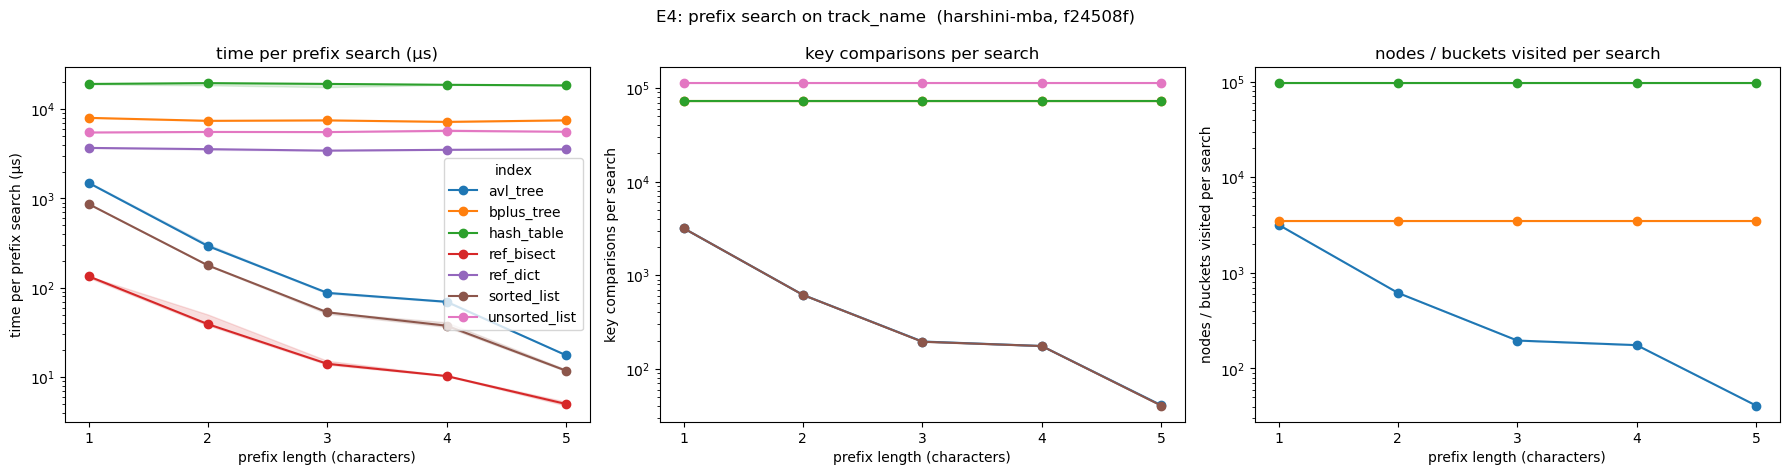

In [16]:
# E4: How does prefix-search cost depend on prefix length?

e4 = df[df["experiment"].str.startswith("E4") & (df["operation"] == "prefix")].copy()
e4["prefix_length"] = pd.to_numeric(e4["operation_param"])

METRICS_E4 = [
    ("us_per_op", "time per prefix search (\u00b5s)"),
    ("comparisons_per_op", "key comparisons per search"),
    ("nodes_visited_per_op", "nodes / buckets visited per search"),
]

# Median (and IQR) per (version, machine, index, prefix length) for time and for each counter.
e4_summary = {
    metric: median_iqr(e4, GROUP + ["index_type", "prefix_length"], value=metric)
    for metric, _ in METRICS_E4
}

for (version, machine), _ in e4_summary["us_per_op"].groupby(GROUP):
    print(f"=== E4 prefix search: code_version={version}, machine={machine} ===")

    # Time table: rows = prefix length, columns = index
    t = e4_summary["us_per_op"]
    t = t[(t["code_version"] == version) & (t["machine_id"] == machine)]
    display(t.pivot(index="prefix_length", columns="index_type", values="median").round(1))

    # Operation-count table (the reference indexes keep no counters, so they are absent here)
    c = e4_summary["comparisons_per_op"]
    c = c[(c["code_version"] == version) & (c["machine_id"] == machine)]
    display(c.pivot(index="prefix_length", columns="index_type", values="median").dropna(axis=1, how="all").round(1))

    fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
    for ax, (metric, label) in zip(axes, METRICS_E4):
        m = e4_summary[metric]
        m = m[(m["code_version"] == version) & (m["machine_id"] == machine)]
        plot_lines(ax, m, x="prefix_length", logx=False)
        ax.set_xticks(sorted(e4["prefix_length"].dropna().unique()))
        ax.set_xlabel("prefix length (characters)")
        ax.set_ylabel(label)
        ax.set_title(label)
    axes[0].legend(title="index")
    fig.suptitle(f"E4: prefix search on track_name  ({machine}, {version})")
    plt.tight_layout()
    plt.show()

# E5 Analysis

In [ ]:
# E5: Does the order keys arrive in matter?

# E5 ANALYSIS TO WRITE:
# - group by code_version and machine_id
# - for each index and arrange order:
# - analyze build time, lookup time, height, rotations and splits.

=== E5 key order: code_version=3d6cb30-dirty, machine=kimberly-mb ===


build_us  lookup_us  height  rotations  \
n_keys insert_order  index_type                                              
10000  nearly_sorted avl_tree          13.34       1.44    20.0    84038.0   
                     bplus_tree         2.86       2.80     4.0        0.0   
                     hash_table         3.33       0.58     NaN        0.0   
                     ref_bisect         0.74       0.57     NaN        NaN   
                     ref_dict           0.23       0.14     NaN        NaN   
...                                      ...        ...     ...        ...   
100000 sorted        hash_table        86.70       3.19     NaN        0.0   
                     ref_bisect         1.34       1.73     NaN        NaN   
                     ref_dict           0.52       0.62     NaN        NaN   
                     sorted_list        3.16    6800.79     NaN        0.0   
                     unsorted_list      0.20    5697.04     NaN        0.0   

                                    splits  
n_keys insert_order  index_type             
10000  nearly_sorted avl_tree          0.0  
                     bplus_tree      616.0  
                     hash_table        0.0  
                     ref_bisect        NaN  
                     ref_dict          NaN  
...                                    ...  
100000 sorted        hash_table        0.0  
                     ref_bisect        NaN  
                     ref_dict          NaN  
                     sorted_list       0.0  
                     unsorted_list     0.0  

[84 rows x 5 columns]

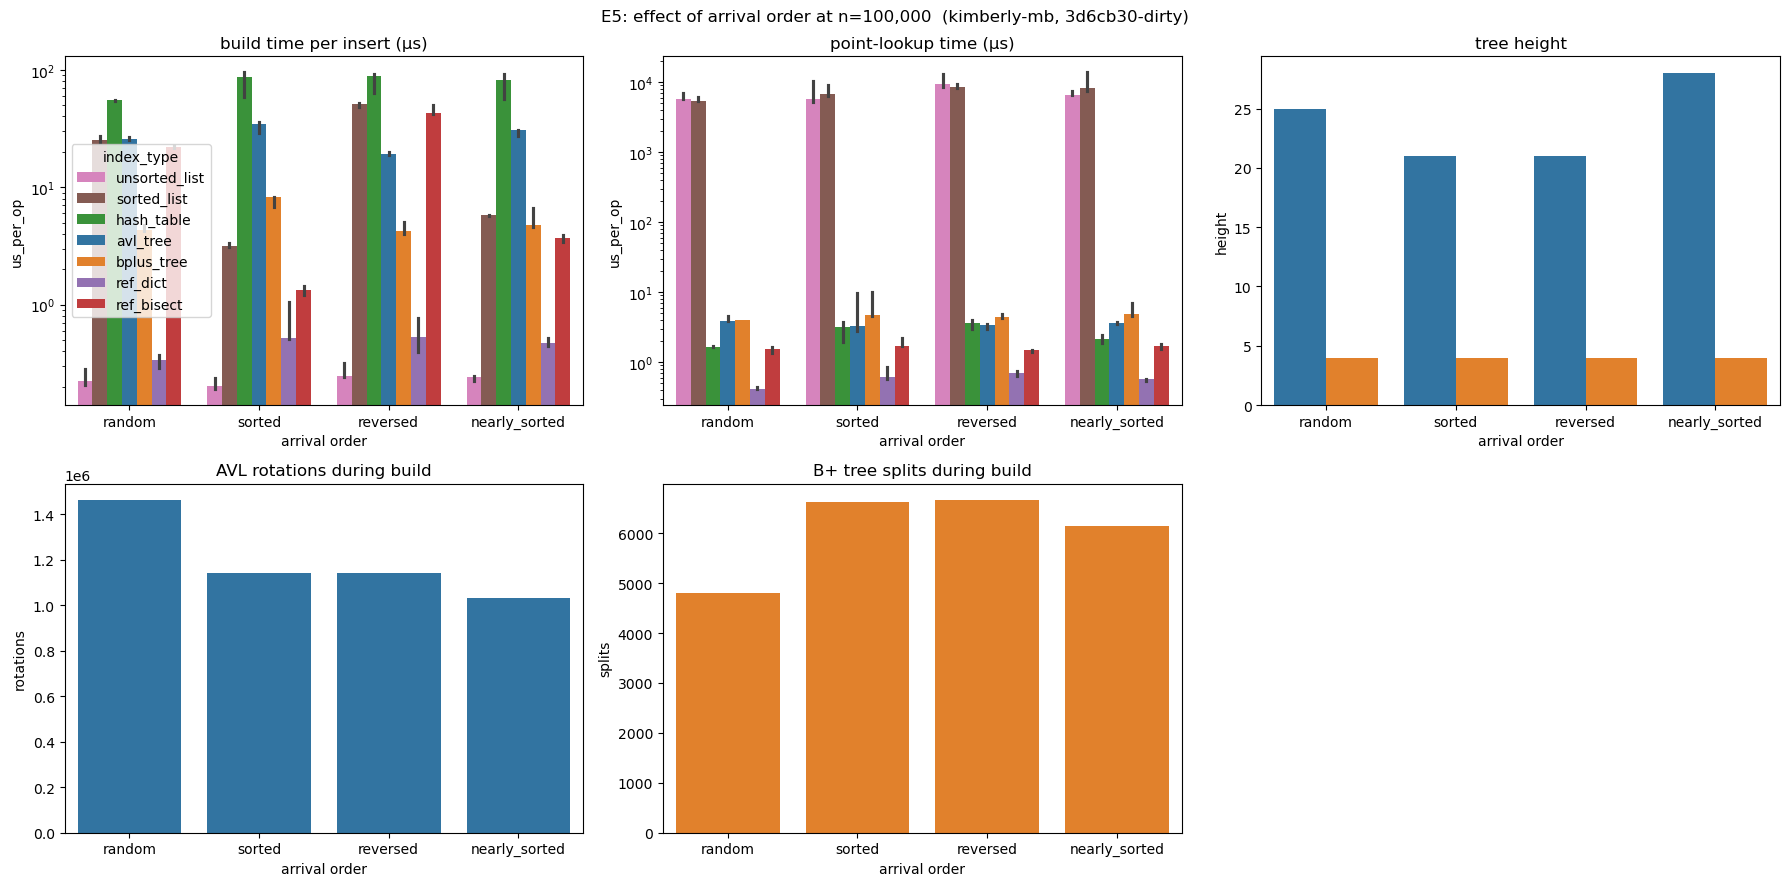

In [17]:
# E5: Does the order keys arrive in matter?

ORDER = ["random", "sorted", "reversed", "nearly_sorted"]

e5 = df[df["experiment"].str.startswith("E5")].copy()
KEYS = GROUP + ["index_type", "insert_order", "n_keys"]

# Build rows carry build time, height and the build-time rotation/split counts;
# point_hit rows carry lookup time. Medians across replicates.
e5_build = e5[e5["operation"] == "build"].groupby(KEYS).agg(
    build_us=("us_per_op", "median"), height=("height", "median"),
    rotations=("rotations", "median"), splits=("splits", "median"),
).reset_index()
e5_lookup = e5[e5["operation"] == "point_hit"].groupby(KEYS).agg(
    lookup_us=("us_per_op", "median"),
).reset_index()
e5_summary = e5_build.merge(e5_lookup, on=KEYS)


def bar_panel(ax, rows, ycol, title, logy=False):
    """Grouped bars: x = arrival order, one bar per index; bar = median, whisker = IQR across replicates."""
    rows = rows.dropna(subset=[ycol])
    # Drop indexes for which this metric is always 0 (e.g. rotations for every index except the AVL tree).
    rows = rows[rows.groupby("index_type")[ycol].transform("max") > 0]
    ax.set_title(title)
    if rows.empty:
        ax.text(0.5, 0.5, "no data", ha="center", va="center", transform=ax.transAxes)
        return
    sns.barplot(
        data=rows, x="insert_order", y=ycol, hue="index_type", order=ORDER,
        palette=INDEX_COLOURS, estimator="median", errorbar=("pi", 50), ax=ax,
    )
    ax.set_xlabel("arrival order")
    if logy:
        ax.set_yscale("log")


for (version, machine), g in e5_summary.groupby(GROUP):
    print(f"=== E5 key order: code_version={version}, machine={machine} ===")

    # All sizes, all orders: build time, lookup time, height, rotations, splits
    display(
        g.set_index(["n_keys", "insert_order", "index_type"])[["build_us", "lookup_us", "height", "rotations", "splits"]]
        .sort_index().round(2)
    )

    # Plots use the largest n, where order effects are clearest.
    n_max = g["n_keys"].max()
    rows = e5[(e5["code_version"] == version) & (e5["machine_id"] == machine) & (e5["n_keys"] == n_max)]
    build_rows = rows[rows["operation"] == "build"]
    lookup_rows = rows[rows["operation"] == "point_hit"]

    fig, axes = plt.subplots(2, 3, figsize=(18, 9))
    bar_panel(axes[0, 0], build_rows, "us_per_op", "build time per insert (\u00b5s)", logy=True)
    bar_panel(axes[0, 1], lookup_rows, "us_per_op", "point-lookup time (\u00b5s)", logy=True)
    bar_panel(axes[0, 2], build_rows, "height", "tree height")
    bar_panel(axes[1, 0], build_rows, "rotations", "AVL rotations during build")
    bar_panel(axes[1, 1], build_rows, "splits", "B+ tree splits during build")
    axes[1, 2].axis("off")
    for ax in axes.ravel()[1:]:  # one shared legend, on the first panel
        if ax.get_legend() is not None:
            ax.get_legend().remove()
    fig.suptitle(f"E5: effect of arrival order at n={n_max:,}  ({machine}, {version})")
    plt.tight_layout()
    plt.show()

# E6 Analysis

In [13]:
# E6: What B+ tree order is best, and does the answer depend on the operation?

# E6 ANALYSIS TO WRITE:
# - group by code_version and machine_id
# - for each order of B+ tree:
# - build memory cost
# - point look up time cost
# - range queries time cost
# - create 3 different line plots summarizing each result 

=== E6 B+ tree order: code_version=3d6cb30-dirty, machine=kimberly-mb ===


series,build_tempo,build_track_id,point_hit,point_miss,range
order,,,,,
3,8.886,12.610,11.233,7.044,37786.816
4,7.877,11.619,10.828,5.218,24359.694
8,7.470,9.008,7.851,3.849,12032.138
16,7.063,10.535,6.142,3.753,10315.382
32,5.562,6.490,5.504,3.114,6716.757
64,3.070,4.144,3.895,2.611,4248.328
128,3.522,5.002,5.408,3.166,4286.606
256,2.851,4.638,4.446,3.039,4369.364
512,2.953,4.907,4.264,2.891,3864.815


series,build_tempo,build_track_id,point_hit,point_miss,range
best order,256,64,64,64,512


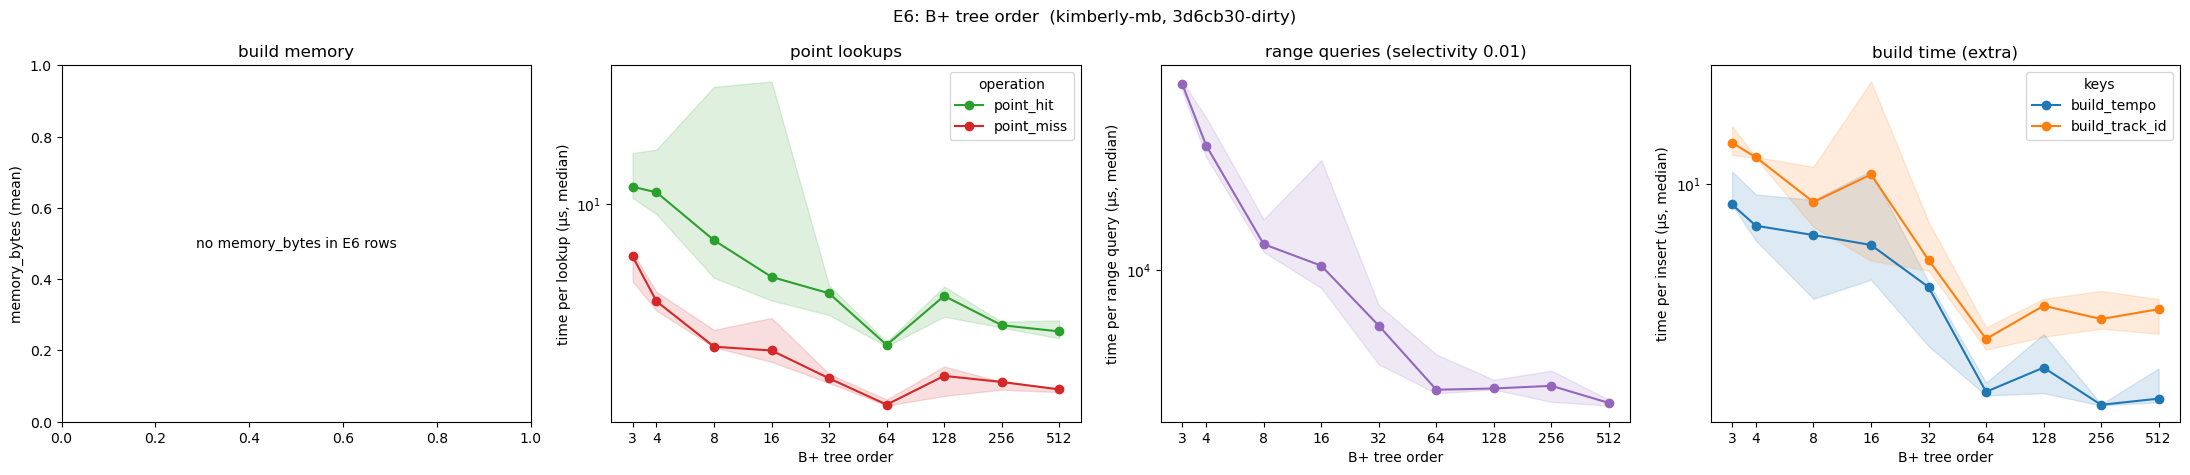

In [18]:
# E6: What B+ tree order is best, and does the answer depend on the operation?
from matplotlib.ticker import ScalarFormatter

e6 = df[df["experiment"].str.startswith("E6")].copy()
e6["order"] = e6["index_param"].str.extract(r"order=(\d+)")[0].astype(int)

# One series per measured operation; build is reported separately for each key column.
e6["series"] = np.where(e6["operation"] == "build", "build_" + e6["key_column"], e6["operation"])

e6_summary = median_iqr(e6, GROUP + ["series", "order"])
SERIES_COLOURS = {s: plt.get_cmap("tab10")(i) for i, s in enumerate(sorted(e6["series"].unique()))}


def order_axis(ax, orders):
    ax.set_xscale("log", base=2)
    ax.set_xticks(orders)
    ax.xaxis.set_major_formatter(ScalarFormatter())
    ax.minorticks_off()
    ax.set_xlabel("B+ tree order")


for (version, machine), g in e6_summary.groupby(GROUP):
    print(f"=== E6 B+ tree order: code_version={version}, machine={machine} ===")
    orders = sorted(g["order"].unique())

    # Median us/op for every operation at every order, and the order with the lowest cost for each
    table = g.pivot(index="order", columns="series", values="median")
    display(table.round(3))
    display(table.idxmin().rename("best order").to_frame().T)

    fig, axes = plt.subplots(1, 4, figsize=(22, 4.8))

    # 1) Build memory
    mem = e6[(e6["code_version"] == version) & (e6["machine_id"] == machine)
             & (e6["operation"] == "build")].dropna(subset=["memory_bytes"])
    ax = axes[0]
    if mem.empty:
        ax.text(0.5, 0.5, "no memory_bytes in E6 rows", ha="center", va="center", transform=ax.transAxes)
    else:
        mem = mem.groupby(["key_column", "order"], as_index=False)["memory_bytes"].mean()
        for key_column, s in mem.groupby("key_column"):
            ax.plot(s["order"], s["memory_bytes"], marker="o", label=key_column)
        ax.set_yscale("log")
        ax.legend(title="keys")
        order_axis(ax, orders)
    ax.set_title("build memory")
    ax.set_ylabel("memory_bytes (mean)")

    # 2) Point lookups: hits and misses
    ax = axes[1]
    plot_lines(ax, g[g["series"].isin(["point_hit", "point_miss"])], x="order", by="series",
               logx=False, colours=SERIES_COLOURS)
    order_axis(ax, orders)
    ax.set_title("point lookups")
    ax.set_ylabel("time per lookup (\u00b5s, median)")
    ax.legend(title="operation")

    # 3) Range queries (selectivity 0.01)
    ax = axes[2]
    plot_lines(ax, g[g["series"] == "range"], x="order", by="series", logx=False, colours=SERIES_COLOURS)
    order_axis(ax, orders)
    ax.set_title("range queries (selectivity 0.01)")
    ax.set_ylabel("time per range query (\u00b5s, median)")

    # 4) Extra: build time (the README's question is whether the best order depends on the operation)
    ax = axes[3]
    plot_lines(ax, g[g["series"].str.startswith("build_")], x="order", by="series", logx=False,
               colours=SERIES_COLOURS)
    order_axis(ax, orders)
    ax.set_title("build time (extra)")
    ax.set_ylabel("time per insert (\u00b5s, median)")
    ax.legend(title="keys")

    fig.suptitle(f"E6: B+ tree order  ({machine}, {version})")
    plt.tight_layout()
    plt.show()